In [ ]:
# EfficientNetB0

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout , Rescaling
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
# this codet to load datasets using image_dataset_from_directory (without generators)
import tensorflow as tf
import numpy as np

train_path = r"flowers_split\train"
val_path   = r"flowers_split\validation"
test_path  = r"flowers_split\test"

IMG_SIZE = (150, 150)
BATCH_SIZE = 32 

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False 
)


Found 3452 files belonging to 5 classes.
Found 430 files belonging to 5 classes.
Found 435 files belonging to 5 classes.


In [3]:
# Display random images from each dataset to verify loading
def dataset_to_numpy(ds):
    x_list = []
    y_list = []
    for images, labels in ds:
        x_list.append(images.numpy())
        y_list.append(labels.numpy())
    return np.concatenate(x_list), np.concatenate(y_list)

x_train, y_train = dataset_to_numpy(train_ds)
x_val, y_val     = dataset_to_numpy(val_ds)
x_test, y_test   = dataset_to_numpy(test_ds)

x_train = x_train / 255.0
x_val   = x_val / 255.0
x_test  = x_test / 255.0

def display_random_images(x_data, y_data, dataset_name):
    fig, axes = plt.subplots(2, 3, figsize=(8, 6))
    fig.suptitle(f'Random Images from {dataset_name} Dataset', fontsize=16)

    for ax in axes.flat:  #flat
        idx = np.random.randint(0, len(x_data))
        img = x_data[idx]
        label_idx = np.argmax(y_data[idx])
        ax.imshow(img)
        ax.set_title(f"Label: {label_idx}")
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()
    

In [4]:
#Callbacks to improve training and manage overfitting 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback , ModelCheckpoint


class StopHighAcc(Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('accuracy', 0) >= 0.98:
            print(f"Stopping training: accuracy reached {logs['accuracy']*100:.2f}%")
            self.model.stop_training = True

# Early stopping with restore best weights and print
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True,
    verbose=1 
)

# Reduce LR on plateau with print
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)
# Model checkpoint to save best model based on val_loss improvement 
#the model is automatically saved whenever val_loss improves.
checkpoint = ModelCheckpoint(
    "best_model.keras", 
    monitor="val_loss", 
    save_best_only=True,
    verbose=1
)


# List of callbacks
callbacks_list = [early_stop, reduce_lr, StopHighAcc(), checkpoint]


In [5]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, test_ds, class_names=None):
 
    predictions = model.predict(test_ds)
    y_pred = np.argmax(predictions, axis=1)

    y_true = np.concatenate([np.argmax(y, axis=1) for x, y in test_ds])

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, target_names=class_names))

    #Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

    return y_true, y_pred


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Function to display predictions on random images from the test dataset to verify model performance
def display_predictions(model, test_ds, train_ds, num_images=6, figsize=(8, 6)):

    class_names = train_ds.class_names  
    
    # Make predictions on test dataset
    predictions = model.predict(test_ds)
    predicted_classes = np.argmax(predictions, axis=1)
    
    # Get actual labels and images from test dataset
    actual_labels = []
    images = []
    for image_batch, label_batch in test_ds:
        actual_labels.extend(np.argmax(label_batch.numpy(), axis=1))
        images.extend(image_batch.numpy())
    
    actual_labels = np.array(actual_labels)
    images = np.array(images)
    
    # Select random indices
    random_indices = np.random.choice(len(images), num_images, replace=False)
    # Calculate grid layout to display images and predictions
    cols = 3
    rows = (num_images + cols - 1) // cols
    
    plt.figure(figsize=figsize)
    # Display images with predictions 
    for idx, i in enumerate(random_indices):
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(images[i])
        
        predicted_label = class_names[predicted_classes[i]]
        actual_label = class_names[actual_labels[i]]
        
        # The color green if correct, red if wrong
        color = 'green' if predicted_classes[i] == actual_labels[i] else 'red'
        
        plt.title(f'Pred: {predicted_label}\nActual: {actual_label}', 
                  color=color, fontsize=11)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    accuracy = np.mean(predicted_classes == actual_labels)
    print(f'\nTest Accuracy:{accuracy * 100:.2f}%')
    
    # Print detailed predictions for the random images
    print("\nDetailed Predictions:")
    print("-" * 50)
    for idx, i in enumerate(random_indices):
        status = "Rigth" if predicted_classes[i] == actual_labels[i] else "Wrong"
        print(f"Image {idx+1} {status}: Predicted: {class_names[predicted_classes[i]]:<15} | "
              f"Actual: {class_names[actual_labels[i]]:<15}")
    
    return {
        'predictions': predicted_classes,
        'actual_labels': actual_labels,
        'accuracy': accuracy,
        'class_names': class_names
    }



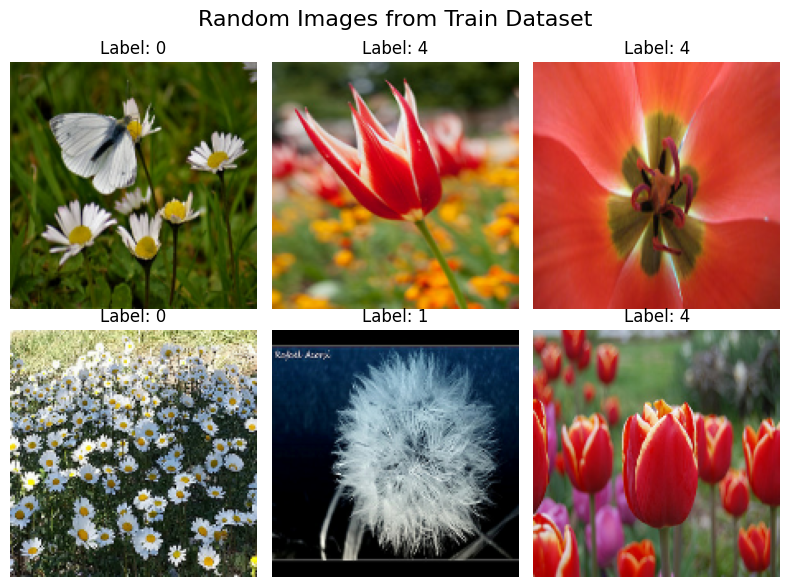

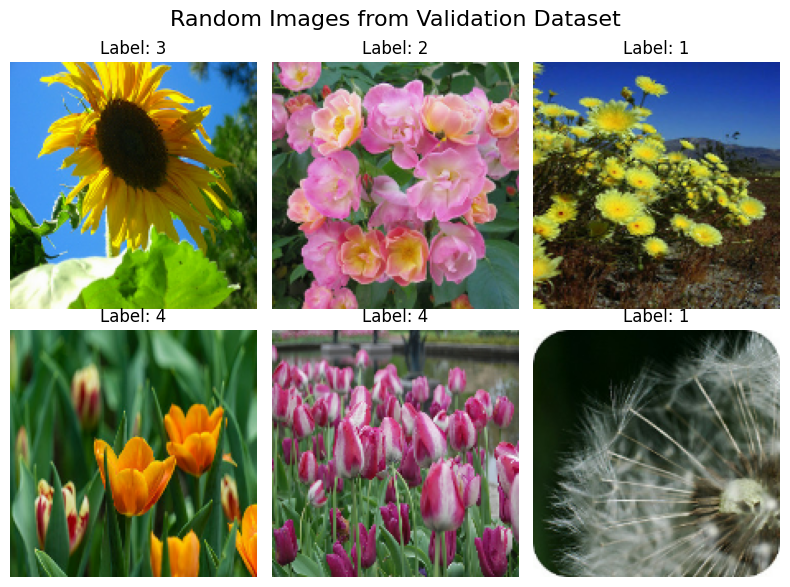

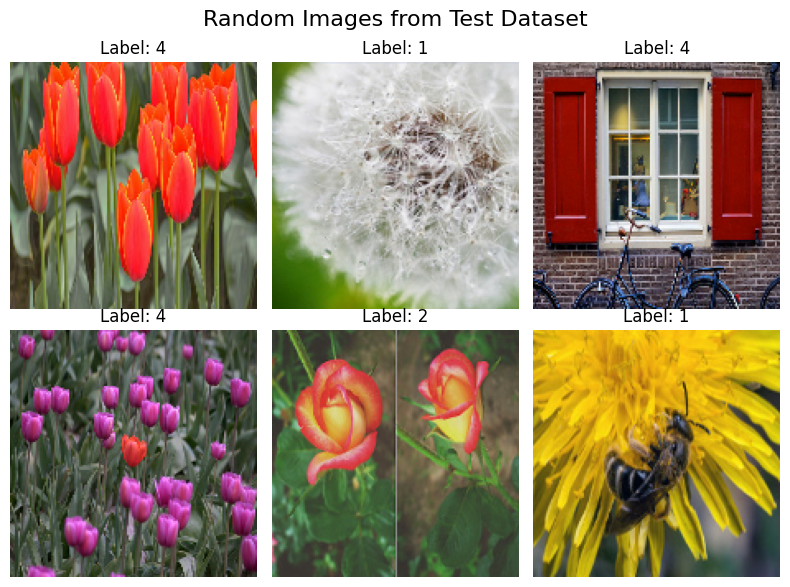

In [7]:
#Check the images loaded correctly 
display_random_images(x_train, y_train, "Train")
display_random_images(x_val, y_val, "Validation")
display_random_images(x_test, y_test, "Test")

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.3),
    layers.RandomShear(0.2),
    tf.keras.layers.RandomContrast(0.3),
    tf.keras.layers.RandomBrightness(0.2),
])

In [9]:
input_shape = (150, 150, 3)
inputs = layers.Input(shape=input_shape)

In [ ]:
# Model EfficientNetB0 without pre-trained weights 
x = Rescaling(1./255)(inputs)
x = data_augmentation(x)
 
enb0_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights=None,
    input_tensor=inputs  
)

x = enb0_base.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(5, activation='softmax')(x)

model = models.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_list
)


Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2587 - loss: 1.7858
Epoch 1: val_loss improved from None to 1.65680, saving model to best_model.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - accuracy: 0.2671 - loss: 1.6977 - val_accuracy: 0.2442 - val_loss: 1.6568 - learning_rate: 0.0010
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3170 - loss: 1.5834
Epoch 2: val_loss did not improve from 1.65680
108/108 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.3160 - loss: 1.5572 - val_accuracy: 0.2442 - val_loss: 1.9203 - learning_rate: 0.0010
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3618 - loss: 1.4663
Epoch 3: val_loss did not improve from 1.65680
108/108 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.3931 - loss: 1.4250 - val_accuracy: 0.3419 - val_loss: 2.1904 - learning_rate: 0.0010
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4764 - loss: 1.2518
Epoch 4: val_loss did not improve from 1.65680
108/108 ━━━

In [11]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy for scratch EfficientNetB0: ", test_acc)
print("Test Loss for scratch EfficientNetB0: ", test_loss)


14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 252ms/step - accuracy: 0.6207 - loss: 1.0330
Test Accuracy for scratch EfficientNetB0:  0.6206896305084229
Test Loss for scratch EfficientNetB0:  1.032969355583191


Evaluation of scratch EfficientNetB0: 
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 409ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.70      0.61      0.65        77
   dandelion       0.65      0.77      0.71       106
        rose       0.50      0.20      0.29        79
   sunflower       0.71      0.74      0.72        74
       tulip       0.53      0.71      0.61        99

    accuracy                           0.62       435
   macro avg       0.62      0.61      0.60       435
weighted avg       0.61      0.62      0.60       435



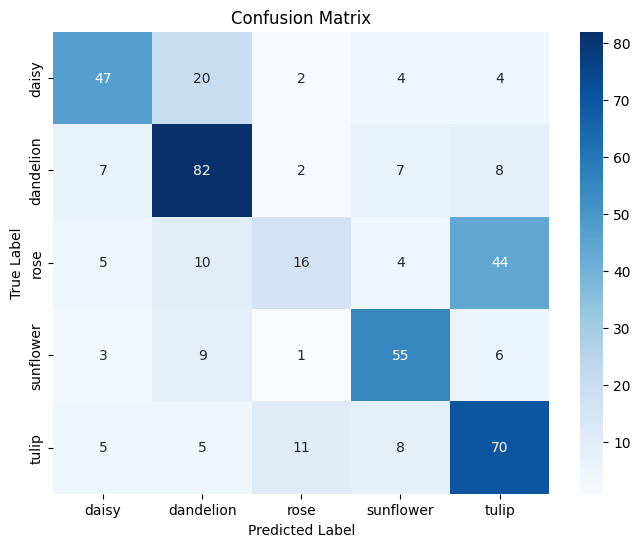

In [12]:
class_names = test_ds.class_names  
print("Evaluation of scratch EfficientNetB0: ")
y_true, y_pred = evaluate_model(model, test_ds, class_names)


14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..245.87503].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..194.00003].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..254.97].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


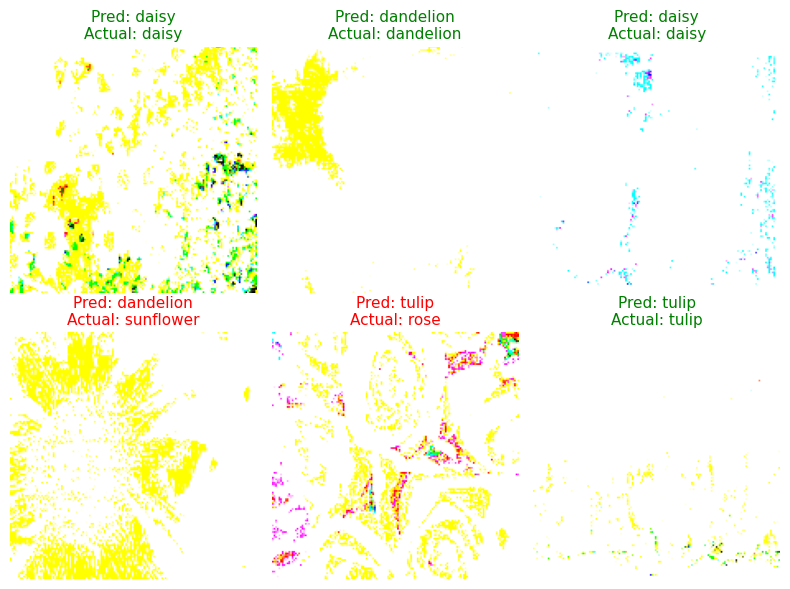


Test Accuracy:62.07%

Detailed Predictions:
--------------------------------------------------
Image 1 Rigth: Predicted: daisy           | Actual: daisy          
Image 2 Rigth: Predicted: dandelion       | Actual: dandelion      
Image 3 Rigth: Predicted: daisy           | Actual: daisy          
Image 4 Wrong: Predicted: dandelion       | Actual: sunflower      
Image 5 Wrong: Predicted: tulip           | Actual: rose           
Image 6 Rigth: Predicted: tulip           | Actual: tulip          


In [13]:
ScratchModelResults = display_predictions(model, test_ds, train_ds, num_images=6)

In [14]:
# The transfer learning model with imagenet weights
y = Rescaling(1./255)(inputs)
y = data_augmentation(y)
Tlenb0_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_tensor=inputs  
)
Tlenb0_base.trainable = False

y = Tlenb0_base.output
y = layers.GlobalAveragePooling2D()(y)
y = layers.Dense(512, activation='relu')(y)
y = layers.Dropout(0.4)(y)
y = layers.Dense(256, activation='relu')(y)
y = layers.Dropout(0.3)(y)
y = layers.Dense(128, activation='relu')(y)
y = layers.Dropout(0.3)(y)
Toutputs = layers.Dense(5, activation='softmax')(y)

Tmodel = models.Model(inputs=inputs, outputs=Toutputs)


Tmodel.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Thistory = Tmodel.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_list
)

Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.6689 - loss: 0.8429
Epoch 1: val_loss improved from 1.04156 to 0.29576, saving model to best_model.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 46s 344ms/step - accuracy: 0.7784 - loss: 0.5946 - val_accuracy: 0.8884 - val_loss: 0.2958 - learning_rate: 0.0010
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.8979 - loss: 0.3185
Epoch 2: val_loss did not improve from 0.29576
108/108 ━━━━━━━━━━━━━━━━━━━━ 35s 285ms/step - accuracy: 0.8925 - loss: 0.3192 - val_accuracy: 0.9047 - val_loss: 0.2963 - learning_rate: 0.0010
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.9227 - loss: 0.2241
Epoch 3: val_loss did not improve from 0.29576
108/108 ━━━━━━━━━━━━━━━━━━━━ 44s 310ms/step - accuracy: 0.9192 - loss: 0.2300 - val_accuracy: 0.9047 - val_loss: 0.3184 - learning_rate: 0.0010
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.9345 - loss: 0.2021
Epoch 4: val_loss improved from 0.295

In [15]:
Ttest_loss, Ttest_accuracy = Tmodel.evaluate(test_ds)

print("Test Loss for transfer EfficientNetB0: ", Ttest_loss)
print("Test Accuracy for transfer EfficientNetB0: ", Ttest_accuracy)

14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 250ms/step - accuracy: 0.8966 - loss: 0.3374
Test Loss for transfer EfficientNetB0:  0.3374037742614746
Test Accuracy for transfer EfficientNetB0:  0.8965517282485962


Evaluation of transfer EfficientNetB0: 
14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 701ms/step

Classification Report:

              precision    recall  f1-score   support

       daisy       0.89      0.87      0.88        77
   dandelion       0.93      0.94      0.93       106
        rose       0.85      0.86      0.86        79
   sunflower       0.89      0.86      0.88        74
       tulip       0.91      0.92      0.91        99

    accuracy                           0.90       435
   macro avg       0.89      0.89      0.89       435
weighted avg       0.90      0.90      0.90       435



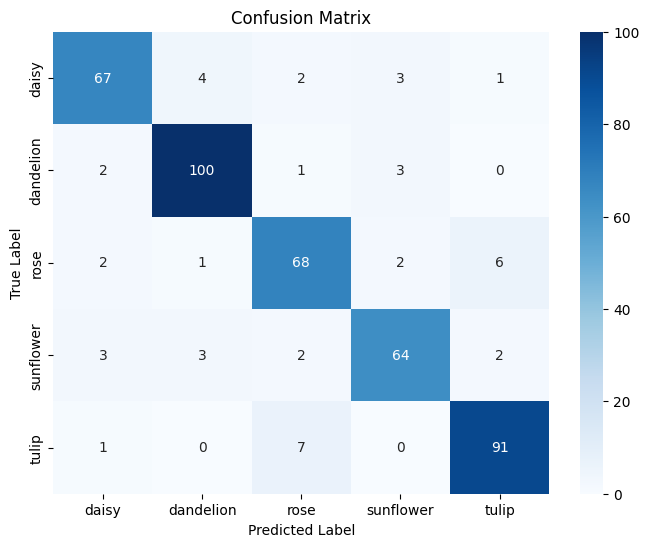

In [16]:
print("Evaluation of transfer EfficientNetB0: ")
y_true, y_pred = evaluate_model(Tmodel, test_ds, class_names)

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..240.49].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..254.73665].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..253.46999].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..251.31001].


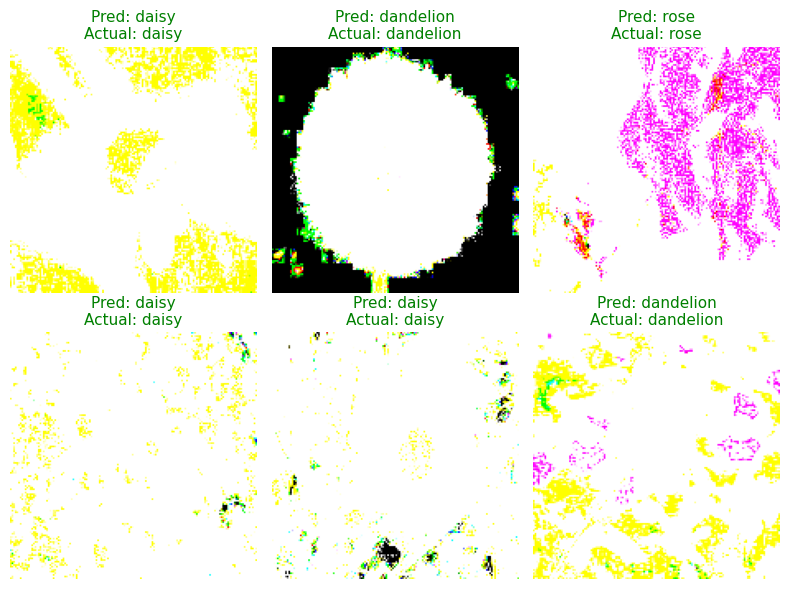


Test Accuracy:89.66%

Detailed Predictions:
--------------------------------------------------
Image 1 Rigth: Predicted: daisy           | Actual: daisy          
Image 2 Rigth: Predicted: dandelion       | Actual: dandelion      
Image 3 Rigth: Predicted: rose            | Actual: rose           
Image 4 Rigth: Predicted: daisy           | Actual: daisy          
Image 5 Rigth: Predicted: daisy           | Actual: daisy          
Image 6 Rigth: Predicted: dandelion       | Actual: dandelion      


In [38]:
TransferModelResults = display_predictions(Tmodel, test_ds, train_ds, num_images=6)

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..254.06203].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..251.73505].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


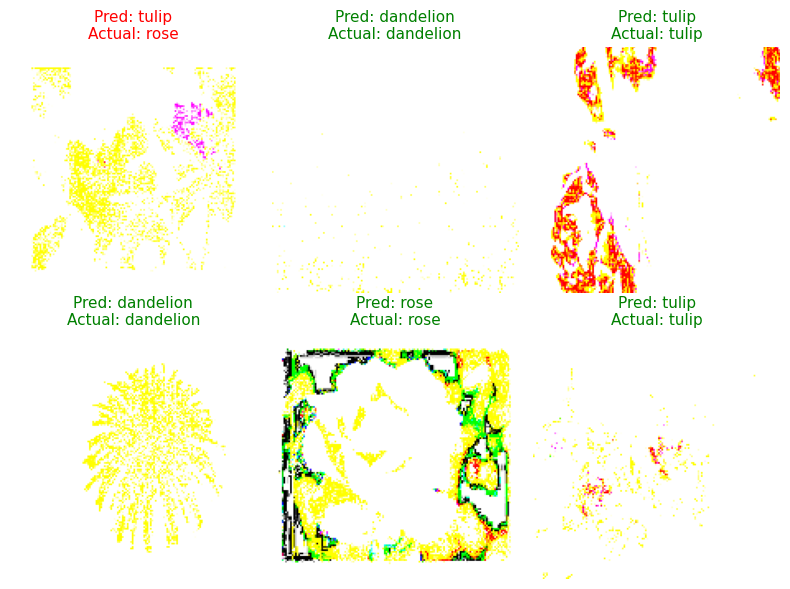


Test Accuracy:89.66%

Detailed Predictions:
--------------------------------------------------
Image 1 Wrong: Predicted: tulip           | Actual: rose           
Image 2 Rigth: Predicted: dandelion       | Actual: dandelion      
Image 3 Rigth: Predicted: tulip           | Actual: tulip          
Image 4 Rigth: Predicted: dandelion       | Actual: dandelion      
Image 5 Rigth: Predicted: rose            | Actual: rose           
Image 6 Rigth: Predicted: tulip           | Actual: tulip          


In [118]:
TransferModelResults = display_predictions(Tmodel, test_ds, train_ds, num_images=6)

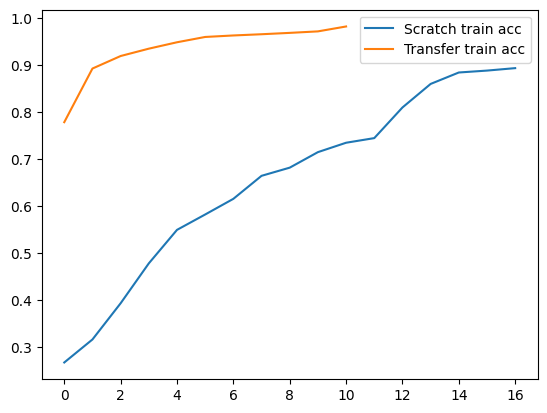

In [18]:
plt.plot(history.history['accuracy'], label='Scratch train acc')
plt.plot(Thistory.history['accuracy'], label='Transfer train acc')
plt.legend()
plt.show()

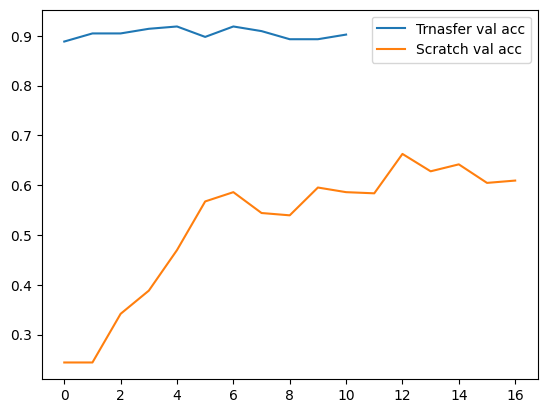

In [19]:

plt.plot(Thistory.history['val_accuracy'], label='Trnasfer val acc') 
plt.plot(history.history['val_accuracy'], label='Scratch val acc')
plt.legend()
plt.show()
